In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

df = pd.read_csv("KaggleV2-May-2016_preprocessed.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (73543, 14)

Columns:
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show']


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,0
1,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,0
2,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,0
3,7.336882e+14,5630279,F,2016-04-27 15:05:12+00:00,2016-04-29 00:00:00+00:00,23,GOIABEIRAS,0,0,0,0,0,0,1
4,3.449833e+12,5630575,F,2016-04-27 15:39:58+00:00,2016-04-29 00:00:00+00:00,39,GOIABEIRAS,0,0,0,0,0,0,1


In [9]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\rahaf\AppData\Local\Programs\Python\Python311\python.exe
3.11.4 (tags/v3.11.4:d2340ef, Jun  7 2023, 05:45:37) [MSC v.1934 64 bit (AMD64)]


In [10]:
import sys
!{sys.executable} -m pip install --user xgboost==2.1.4 --no-deps

  Using cached xgboost-2.1.4-py3-none-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.9 MB 699.0 kB/s eta 0:02:58
   ---------------------------------------- 0.8/124.9 MB 884.1 kB/s eta 0:02:21
   ---------------------------------------- 0.8/124.9 MB 884.1 kB/s eta 0:02:21
   ---------------------------------------- 1.3/124.9 MB 972.7 kB/s eta 0:02:08
    --------------------------------------- 1.6/124.9 MB 1.1 MB/s eta 0:01:57
    --------------------------------------- 1.8/124.9 MB 1.1 MB/s eta 0:01:54
    --------------------------------------- 2.4/124.9 MB 1.2 MB/s eta 0:01:42
    --------------------------------------- 2.9/124.9 MB 1.3 MB/s eta 0:01:31
   - ---------

In [11]:
print("No-show distribution:")
print(df["No-show"].value_counts())

print("\nPercentages:")
print(df["No-show"].value_counts(normalize=True) * 100)

print("\nMissing values:")
print(df.isnull().sum())

No-show distribution:
No-show
0    58677
1    14866
Name: count, dtype: int64

Percentages:
No-show
0    79.785976
1    20.214024
Name: proportion, dtype: float64

Missing values:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64


In [12]:
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])

df["WaitingDays"] = (
    df["AppointmentDay"].dt.normalize()
    - df["ScheduledDay"].dt.normalize()
).dt.days

df["AppointmentWeekday"] = df["AppointmentDay"].dt.dayofweek

# Remove impossible negative waiting times if present
df = df[df["WaitingDays"] >= 0].copy()

print(df[["ScheduledDay", "AppointmentDay",
          "WaitingDays", "AppointmentWeekday"]].head())


               ScheduledDay            AppointmentDay  WaitingDays  \
0 2016-04-29 16:08:27+00:00 2016-04-29 00:00:00+00:00            0   
1 2016-04-29 16:19:04+00:00 2016-04-29 00:00:00+00:00            0   
2 2016-04-29 17:29:31+00:00 2016-04-29 00:00:00+00:00            0   
3 2016-04-27 15:05:12+00:00 2016-04-29 00:00:00+00:00            2   
4 2016-04-27 15:39:58+00:00 2016-04-29 00:00:00+00:00            2   

   AppointmentWeekday  
0                   4  
1                   4  
2                   4  
3                   4  
4                   4  


In [13]:
features = [
    "Age",
    "Scholarship",
    "Hipertension",
    "Diabetes",
    "Alcoholism",
    "Handcap",
    "SMS_received",
    "WaitingDays",
    "AppointmentWeekday"
]

X = df[features].copy()
y = df["No-show"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (73540, 9)
y shape: (73540,)


,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,WaitingDays,AppointmentWeekday
0,56,0,0,0,0,0,0,0,4
1,62,0,0,0,0,0,0,0,4
2,8,0,0,0,0,0,0,0,4
3,23,0,0,0,0,0,0,2,4
4,39,0,0,0,0,0,0,2,4


In [14]:
# Reload the original no-show dataset
df = pd.read_csv("KaggleV2-May-2016.csv")

# Check the ORIGINAL target values
print("Original No-show values:")
print(df["No-show"].value_counts())

# Convert target correctly
df["No-show"] = (
    df["No-show"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"no": 0, "yes": 1})
)

# Remove rows only if target could not be converted
df = df.dropna(subset=["No-show"])
df["No-show"] = df["No-show"].astype(int)

print("\nTarget after conversion:")
print(df["No-show"].value_counts())

Original No-show values:
No-show
No     88208
Yes    22319
Name: count, dtype: int64

Target after conversion:
No-show
0    88208
1    22319
Name: count, dtype: int64


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

Training samples: 58832
Testing samples: 14708

Training target distribution:
No-show
0    0.797899
1    0.202101
Name: proportion, dtype: float64


In [16]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:")
print(y_train.value_counts(normalize=True))

print("\nAfter SMOTE:")
print(y_train_smote.value_counts(normalize=True))

print("\nTraining samples after SMOTE:", X_train_smote.shape[0])

Before SMOTE:
No-show
0    0.797899
1    0.202101
Name: proportion, dtype: float64

After SMOTE:
No-show
0    0.5
1    0.5
Name: proportion, dtype: float64

Training samples after SMOTE: 93884


In [19]:
print("Full target:")
print(y.value_counts(dropna=False))

print("\nTraining target:")
print(y_train.value_counts(dropna=False))

print("\nUnique values:")
print(y_train.unique())

Full target:
No-show
0    58677
1    14863
Name: count, dtype: int64

Training target:
No-show
0    46942
1    11890
Name: count, dtype: int64

Unique values:
[0 1]


In [29]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_smote, y_train_smote)

log_pred = log_model.predict(X_test_scaled)
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]

print("LOGISTIC REGRESSION")
print(classification_report(y_test, log_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, log_prob))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.86      0.70      0.77     11735
           1       0.32      0.57      0.41      2973

    accuracy                           0.67     14708
   macro avg       0.59      0.63      0.59     14708
weighted avg       0.76      0.67      0.70     14708

ROC-AUC: 0.6838363765581756


In [31]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_smote, y_train_smote)

rf_pred = rf_model.predict(X_test_scaled)
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("RANDOM FOREST")
print(classification_report(y_test, rf_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_prob))

RANDOM FOREST
              precision    recall  f1-score   support

           0       0.92      0.55      0.69     11735
           1       0.31      0.80      0.45      2973

    accuracy                           0.60     14708
   macro avg       0.61      0.68      0.57     14708
weighted avg       0.79      0.60      0.64     14708

ROC-AUC: 0.7303330027053593


In [22]:
from xgboost import XGBClassifier

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("XGBOOST")
print(classification_report(y_test, xgb_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, xgb_prob))

XGBOOST
              precision    recall  f1-score   support

           0       0.92      0.53      0.67     11735
           1       0.31      0.83      0.45      2973

    accuracy                           0.59     14708
   macro avg       0.62      0.68      0.56     14708
weighted avg       0.80      0.59      0.62     14708

ROC-AUC: 0.732812927482121


In [23]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],

    "Precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, xgb_pred)
    ],

    "Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, xgb_pred)
    ],

    "F1 Score": [
        f1_score(y_test, log_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, xgb_pred)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, xgb_prob)
    ]
})

results = results.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.5868,0.3069,0.8298,0.4481,0.7328
1,Random Forest,0.5925,0.3088,0.8200,0.4486,0.7327
2,Logistic Regression,0.6729,0.3238,0.5681,0.4125,0.6833


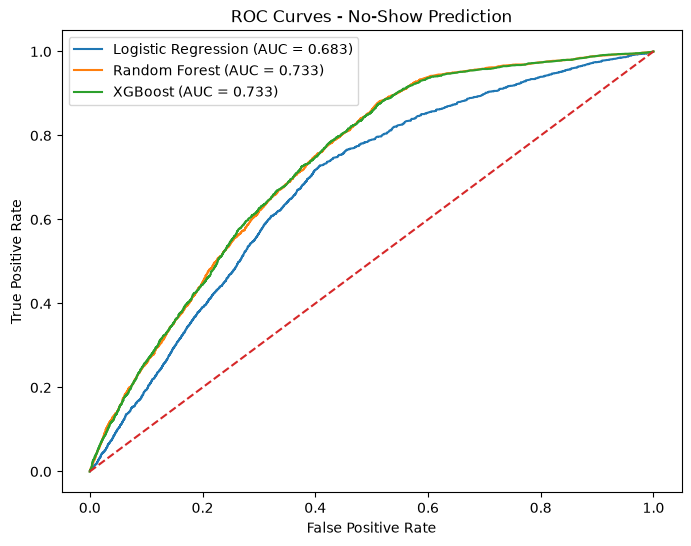

In [24]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Logistic Regression
fpr_log, tpr_log, _ = roc_curve(y_test, log_prob)
auc_log = auc(fpr_log, tpr_log)
plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {auc_log:.3f})")

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
auc_rf = auc(fpr_rf, tpr_rf)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_prob)
auc_xgb = auc(fpr_xgb, tpr_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {auc_xgb:.3f})")

# Random classifier baseline
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - No-Show Prediction")
plt.legend()
plt.show()

,Feature,Importance
7,WaitingDays,0.619269
6,SMS_received,0.258439
0,Age,0.081677
8,AppointmentWeekday,0.040615
1,Scholarship,0.000000
4,Alcoholism,0.000000
3,Diabetes,0.000000
2,Hipertension,0.000000
5,Handcap,0.000000


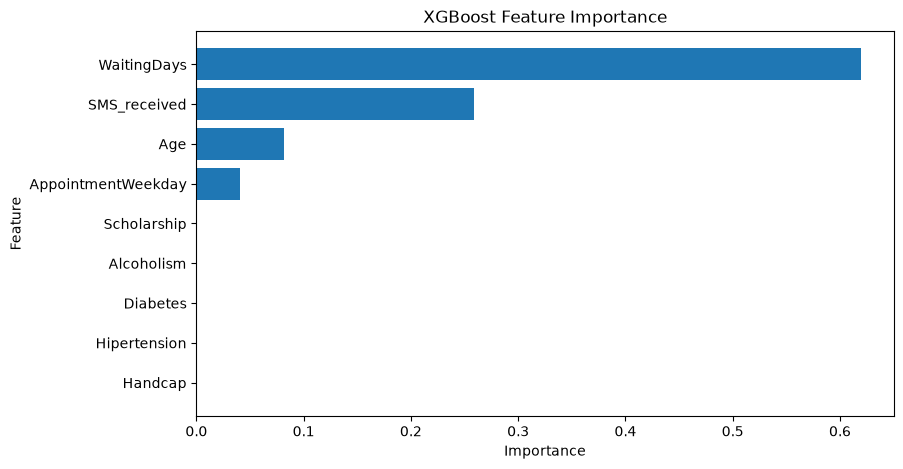

In [25]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()
plt.show()

XGBoost Confusion Matrix:
[[6163 5572]
 [ 506 2467]]


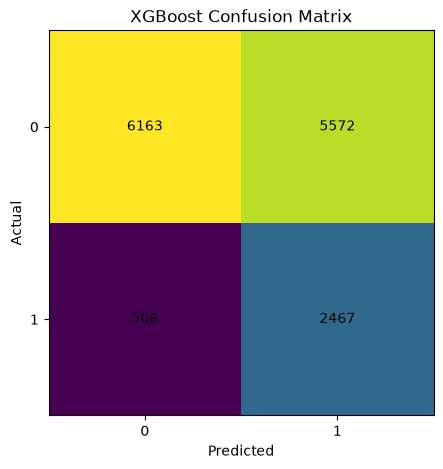

In [26]:
cm = confusion_matrix(y_test, xgb_pred)

print("XGBoost Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(cm)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j],
                ha="center", va="center")

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("XGBoost Confusion Matrix")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

plt.show()